**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

In [1]:
import itertools as it
import os

import biom
from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
from matplotlib import ticker
import matplotlib.image as mpimg
from PIL import Image

import numpy as np
import pandas as pd
import scipy
import seaborn as sn
import skbio
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.phylogeny.actions as q2_phylogeny
# import qiime2.plugins.empress.actions as q2_empress

import scripts.alpha_plots as ap

from scripts.ancom_colors import *

rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

%matplotlib inline

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}
abx_colors2 = {i: color for i, color in enumerate(colors)}

# Draft figure

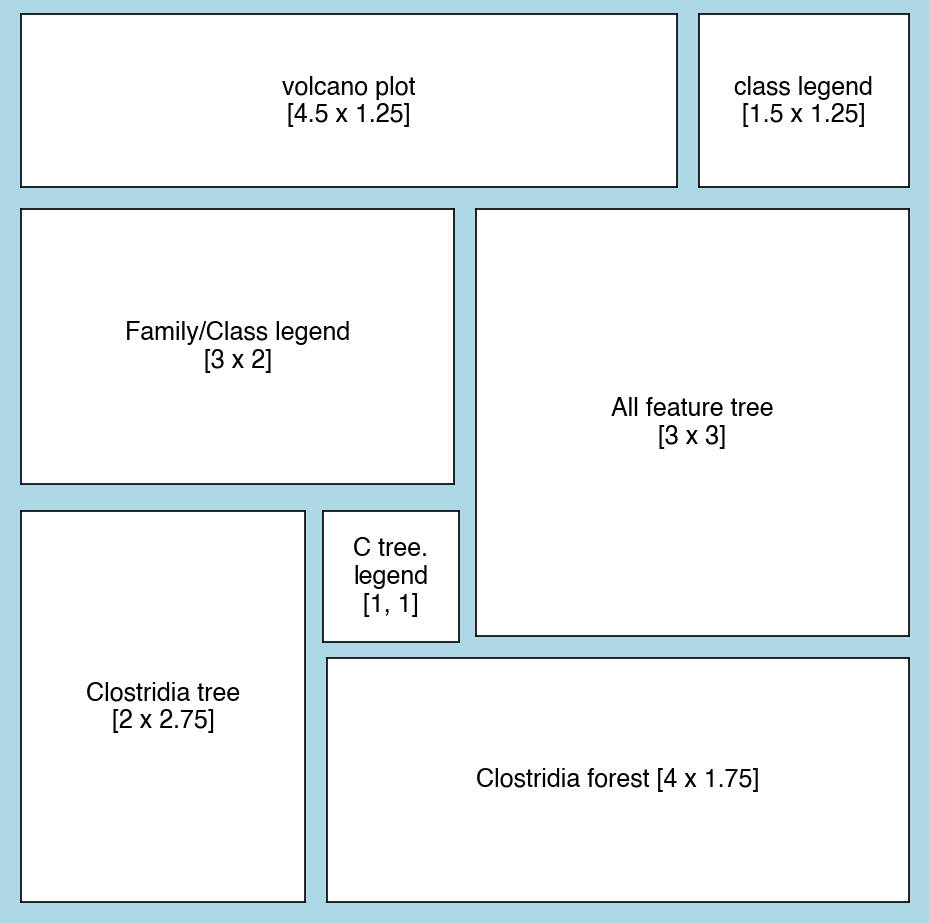

In [3]:
def _label_fig(fig, label, rotation=0):
    """
    Helper to label function
    """
    ax = fig.add_subplot(1,1,1)
    ax.xaxis.set_tick_params(**ap.hide_axes)
    ax.yaxis.set_tick_params(**ap.hide_axes)
    ax.text(0.5, 0.5, label, rotation=rotation, ha='center', va='center', size=12)

fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 6), facecolor='lightblue')
fig0, fig1 = fig.subfigures(2, 1, height_ratios=[1.25, 3 + 1.75], facecolor='None')
figvol, figvoll = fig0.subfigures(1, 2, width_ratios=[4.5, 1.5], facecolor='None')
fig10, fig11 = fig1.subfigures(2, 1, height_ratios=[3, 1.75], facecolor='None')
fig100, figatree = fig10.subfigures(1, 2, width_ratios=[1, 1], facecolor='None')
[figal, _] = fig100.subfigures(2, 1, height_ratios=[2, 1], facecolor='None')
[_, figclf] = fig11.subfigures(1, 2, width_ratios=[2, 4], facecolor='None')
[_, fig12] = fig1.subfigures(2, 1, height_ratios=[2, 2.75], facecolor='None')
[fig120, fig121, _] = fig12.subfigures(1, 3, width_ratios=[2, 1, 3], facecolor='None')
[figclfl, _] = fig121.subfigures(2, 1, height_ratios=[1, 1.75], facecolor='None')

_label_fig(figvol, 'volcano plot\n[4.5 x 1.25]')
_label_fig(figvoll, 'class legend\n[1.5 x 1.25]')
_label_fig(figatree, 'All feature tree\n[3 x 3]')
_label_fig(figal, 'Family/Class legend\n[3 x 2]')
_label_fig(figclf, 'Clostridia forest [4 x 1.75]')
_label_fig(fig120, 'Clostridia tree\n[2 x 2.75]')
_label_fig(figclfl, 'C tree.\nlegend\n[1, 1]')

# Data

## Metadata

In [4]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()

## Table

In [5]:
table_q2 = Artifact.load('final-data/02.tables/matched-genome-gtdb.qza')

table2 = table_q2.view(biom.Table).copy().norm(axis='sample', inplace=False)
table2 = table2.transform(lambda v, id_, md: (v > 2.5e-5) * 1, axis='sample')
table2.add_metadata(meta.to_dict(orient='index'))
table2 = table2.collapse(lambda id_, md: md['host_subject_id'], norm=True)
table2.filter(lambda v, id_, md: (v >= 0.2).mean() >= 0.1, axis='observation', inplace=True)
table2
table = table_q2.view(pd.DataFrame)[table2.ids(axis='observation')]
table.shape

(473, 896)

In [6]:
tree_q2 = Artifact.load('final-data/02.tables/matched_tree_gtdb.qza')
taxa_q2 = Artifact.load('final-data/02.tables/matched-taxonomy-gtdb.qza')

In [7]:
os.makedirs('final-data/07.ancom-bc', exist_ok=True)
table.T.to_csv('final-data/07.ancom-bc/table_for_ancom.tsv',
             sep='\t',
            )

# Modeling results

In [8]:
%%bash
# Rscript scripts/ancom-bc/ANCOM-BC-taxa.r
# Rscript scripts/ancom-bc/ANCOM-BC-taxa_adj.r

In [9]:
ancom_raw = pd.read_csv('final-data/07.ancom-bc/follow_up_res.tsv', 
                        sep='\t',
                        dtype=str)
ancom_raw.set_index('taxon', inplace=True)

In [10]:
val_crit = ['passed_ss', 'lfc', 'se', 'W', 'p', 'q', 'diff']
var_names = ['(Intercept)', 'abx_code2', 'extraction_no', 
             'after_travel_na_eu', 'days_inv',]

In [11]:
def _get_stat(col_):
    stat = [v for v in val_crit if (v in col_)][0]
    var = [v for v in var_names if (v in col_)][0]
    val = col_.replace(f'{stat}_{var}', '') 
    return {'stat': stat, 'var': var, 'val': val}

In [12]:
new_cols = pd.DataFrame.from_dict(
    data={col_: _get_stat(col_) for col_ in ancom_raw.columns},
    orient='index')
new_cols.replace({'val': {'_1': '1', 
                          '_2': '2', 
                          '_3': '3',
                          '_4': '4',
                          '_5': '5', 
                          '': '0'}},
                 inplace=True)

We want to clean up the data to make it workable

In [13]:
ancom_res = ancom_raw.copy()
ancom_res.replace({'FALSE': '0', 'TRUE': '1'}, inplace=True)
ancom_res.columns = pd.MultiIndex.from_frame(new_cols)
ancom_res = ancom_res.astype(float)
ancom_res.drop(columns=['extraction_no', 'after_travel_na_eu'], 
                level='var',
                inplace=True)
ancom_res.drop(columns=['(Intercept)'], level='var', inplace=True)
ancom_res = ancom_res.reset_index().melt(id_vars=[('taxon', '', '')])
ancom_res.rename(columns={('taxon', '', ''): 'taxon'}, inplace=True)
ancom_res = ancom_res.pivot(index=['var', 'val', 'taxon'],
                              columns='stat', 
                              values='value')
ancom_res.sort_values('q', inplace=True)
ancom_res
ancom_res['tidy'] = ancom_res.apply(
    lambda x: np.nan if pd.isnull(x['q']) else '{lfc:1.2f} ± {se:1.2f}'.format(**x), 
    axis=1)
def _tidy_p(x):
    if x > 0.01:
        return f'{x:1.2f}'
    elif x > 0.001:
        return f'{x:1.3f}'
    elif x < 1e-16:
        return '<1E-16'
    else:
        return f'{x:1.0E}'
        
ancom_res['q_tidy'] = ancom_res['q'].apply(_tidy_p)

And then we'll make a tidy version fo the results for tables

In [14]:
ancom_res_disp = ancom_res[['lfc', 'se', 'q_tidy']].copy()
ancom_res_disp['lfc'] = ancom_res_disp['lfc'].apply(lambda x: f'{x:1.2f}')
ancom_res_disp['se'] = ancom_res_disp['se'].apply(lambda x: f'{x:1.2f}')

ancom_res_disp.drop(['0'], level='val', inplace=True)
ancom_res_disp.reset_index(['var', 'val'], inplace=True)
ancom_res_disp['name'] = taxa_q2.view(pd.Series)
ancom_res_disp = \
    ancom_res_disp.melt(id_vars=['name', 'var', 'val'],
                        value_vars=['lfc', 'se', 'q_tidy'],
                        var_name='stat')
ancom_res_disp['stat'] = pd.Categorical(ancom_res_disp['stat'], categories=['lfc', 'se', 'q_tidy'], ordered=True)
levels = ['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']
for i, lvl in enumerate(levels):
    ancom_res_disp[lvl] = ancom_res_disp['name'].apply(
        lambda x: x.split(';')[i].split("__", 1)[-1])
ancom_res_disp = \
    ancom_res_disp.pivot(index=levels,
                         columns=['var', 'val', 'stat'],
                         values='value')
ancom_res_disp.sort_index(axis='columns',
                          ascending=[False, True, True],
                          inplace=True)
ancom_res_disp.rename(columns=abx_names, level='val', inplace=True)
ancom_res_disp.rename(columns={'tidy': 'LFC ± sem', 'q_tidy': 'fdr p'},
                      level='stat',
                      inplace=True)
ancom_res_disp.rename(columns={"days_inv": 'Rate of recovery (30 days)-1',
                             'abx_code2': 'Steady state'},
                      level='var',
                      inplace=True)

In [15]:
os.makedirs('output', exist_ok=True)
ancom_res_disp.to_csv('output/tables/table_s6_ancom_bc_recovery.tsv', sep='\t')

## Volcano Panel

In [16]:
ancom_sigs = (ancom_res['q'] <= 0.1).groupby('taxon').sum().to_frame()
ancom_sigs.sort_values('q', ascending=False, inplace=True)
ancom_sigs = pd.concat(axis=1, objs=[
    ancom_sigs, 
    taxa_q2.view(pd.Series).loc[ancom_sigs.index].apply(
        lambda x: pd.Series(x.split(';'))).add_prefix('t')
    ])
table_n = table2.copy().norm(axis='sample').to_dataframe().sparse.to_dense()
ancom_sigs['mean'] = table_n.mean(axis=1)
ancom_sigs['log10_mean'] = np.log10(ancom_sigs['mean'])
ancom_sigs['prev'] = (table_n > 1e-5).mean(axis=1)
ancom_sigs['any_sig'] = ancom_sigs['q'] > 0

In [17]:
top_phyla = pd.DataFrame(
    {'num_feats': ancom_sigs.groupby('t2')['mean'].count(),
     'mean_abund': ancom_sigs.groupby('t2')['mean'].sum(),
     'num_sig': ancom_sigs.groupby('t2')['any_sig'].sum()}
    )
top_phyla = top_phyla.loc[(top_phyla['num_sig'] > 0) & 
                           (top_phyla['mean_abund'] > 0.01)]
top_phyla.sort_values('num_sig', ascending=False, inplace=True)
keep_phyla = top_phyla.index
keep_class = ['c__Clostridia', 'c__Bacteroidia', 'c__Gammaproteobacteria',
              'c__Bacilli', 'c__Negativicutes']

In [18]:
ancom_sigs['t1_group'] = \
    ancom_sigs['t2'].mask(~ancom_sigs['t2'].isin(keep_class), 'c__Other')

In [19]:
top_families = pd.DataFrame(
    {'num_feats': ancom_sigs.groupby(['t1', 't1_group', 't2', 't3', 't4'])['mean'].count(),
     'mean_abund': ancom_sigs.groupby(['t1', 't1_group', 't2', 't3', 't4'])['mean'].sum(),
     'num_sig': ancom_sigs.groupby(['t1', 't1_group', 't2', 't3', 't4'])['any_sig'].sum(),}
    )
top_families = top_families.loc[(top_families['num_sig'] > 0)].copy()
top_families['t1_count'] = 1
top_families.sort_values(by=['num_sig', 'mean_abund'], 
                         ascending=False,
                         inplace=True)
top_families['t1_count'] = \
    top_families.groupby('t1_group')['t1_count'].cumsum() - 1
top_families.set_index('t1_count', append=True, inplace=True)
top_families.sort_index(level=['t1_group', 't1_count'],
                        ascending=True,
                        inplace=True)
keep_families = \
    top_families.index.to_frame().drop([4, 5, 6], level='t1_count')

keep_families = keep_families['t4'].values

In [20]:
ancom_res_v = ancom_res[['lfc', 'q']].copy().reset_index(['var', 'val'])
ancom_res_v['log_q'] = -np.log10(ancom_res_v['q'])
taxonomy = taxa_q2.view(pd.Series).loc[ancom_res_v.index].apply(
                lambda x: pd.Series(x.split(';'))).add_prefix('t')
ancom_res_v['t2'] = \
    taxonomy['t2'].mask(~taxonomy['t2'].isin(keep_class), 'c__Other')
ancom_res_v['t4'] = \
    taxonomy['t4'].mask(~taxonomy['t4'].isin(keep_families), 'f__Other')
ancom_res_v['t4'] = ancom_res_v['t4'].mask(
    ancom_res_v['t4'].isin(['f__Other']) & ancom_res_v['t2'].isin(keep_class), 
    ancom_res_v['t2'])
ancom_res_v['color_f'] = ancom_res_v['t4'].replace(cmap_fam)
ancom_res_v['color_c'] = ancom_res_v['t2'].replace(class_color)
ancom_res_v[['color_f', 'color_c']] = \
    ancom_res_v[['color_f', 'color_c']].mask(ancom_res_v['log_q'] < 1, '#9f9f9f')
ancom_res_v['color_abx'] = ancom_res_v['val'].replace(abx_colors)
ancom_res_v['color_abx_ns'] = ancom_res_v['val'].replace(abx_colors)
ancom_res_v['color_abx'] = \
    ancom_res_v['color_abx'].mask(ancom_res_v['log_q'] < 1, 
                                  ancom_res_v['color_abx_ns'])
ancom_res_v.drop(columns=['color_abx_ns'], inplace=True)
ancom_res_v.set_index(['var', 'val'], append=True, inplace=True)

In [21]:
recovery = ancom_res_v.xs('days_inv', level='var')

In [22]:
hide_axes = dict(left=False, labelleft=False, right=False, labelright=False, labelsize=0, length=0)

In [23]:
def _plot_ancom_volcano(fig, data, palette, scatter_kws=None, 
                        ylabel='-$\\log_{10}$(q)', xlim=None, ylim=None, 
                        bottom=True, title=True):
    """
    Plots the ancom-bc volcano strip
    """
    scatter_kwargs = dict(marker='.', s=2.5, x='lfc', y='log_q')
    if isinstance(scatter_kws, dict):
        scatter_kwargs.update(scatter_kws)

    
    
    gs = fig.add_gridspec(1, 5)
    for i, (abx, df) in enumerate(data.drop(['0'], level='val').groupby('val')):
        if i == 0:
            ax = fig.add_subplot(gs[0, i])
        else:
            ax = fig.add_subplot(gs[0, i], sharex=ax, sharey=ax)
        ax.scatter(**scatter_kwargs, c=palette, data=df)
        ax.yaxis.set_tick_params(left=True, labelleft=(i == 0),
                                 right=False, labelright=False,
                                 labelsize=8)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=bottom,
                                 top=False, labeltop=False,
                                 labelsize=8)
        ax.set_ylabel(ylabel, size=10)
        ax.yaxis.get_label().set_visible(i == 0)
        if title:
            ax.set_title(abx_names[abx], size=8)
        ax.plot([-1.25, 1.25], [1, 1], color='k', linewidth=0.75, zorder=3)
        ax.plot([0, 0], [-0.5, 8.5], color='k', linewidth=0.75, zorder=3)
        ax.set_xlim(-1.4, 1.4)
        ax.set_yticks(np.arange(0, 8.1, 4))

(15.5, -1.0)

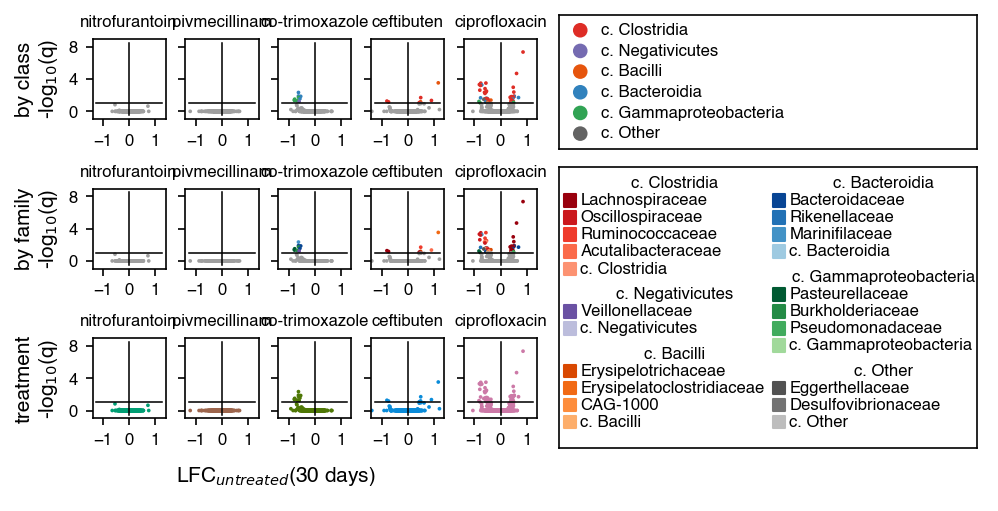

In [24]:
color_cat = {'color_c': 'by class\n-log$_{10}$(q)',
             'color_f': 'by family\n-log$_{10}$(q)',
             'color_abx': 'treatment\n-log$_{10}$(q)'}
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 3.25), facecolor='w')
[[fig, figl], [figx, _]] = figa.subfigures(2, 2, 
                                                    width_ratios=[6.5 - 2.9, 2.9], 
                                                    height_ratios=[3, 0.25])
figs = fig.subfigures(3, 1, width_ratios=[4, ], facecolor='None')
for fig_, (hue, yl) in zip(*(figs, color_cat.items())):
    _plot_ancom_volcano(fig_, recovery, hue, ylabel=yl)
ap._add_labelfig(figx, 'LFC$_{untreated}$(30 days)')

figls = figl.subfigures(2, 1, facecolor='None', height_ratios=[1, 2])
axlc = figls[0].add_subplot(1,1,1)
axlc.xaxis.set_tick_params(**hide_axes)
axlc.yaxis.set_tick_params(**hide_axes)
axlc.set_xlim(0, 2)
axlc.set_ylim(-0.75, 5.75)
axlc.scatter(np.ones(6) * 0.1, 5 - np.arange(6), marker='o',
             c=pd.Series(class_color)[class_order])
for y, cl in enumerate(class_order):
    axlc.text(0.2, 5 - y, cl.replace("__", '. '), 
              size=8, ha='left', va='center')

axlf = figls[1].add_subplot(1,1,1)
axlf.xaxis.set_tick_params(**hide_axes)
axlf.yaxis.set_tick_params(**hide_axes)
axlf.scatter(x='x', y='y', c='color', marker='s', data=cmap2)
axlf.set_xlim(-0.05, 1.95)
for l_, df in cmap2.iterrows():
    axlf.text(df['x'] + 0.05, df['y'], 
              l_.replace('c__', 'c. ').replace('f__', '').replace('_', ' '),
              ha='left', va='center', size=8)
for phy_, [x, y] in cmap2.groupby('class')[['x', 'y']].first().iterrows():
    axlf.text(x + 0.5, y - 1, phy_.replace("__", '. ').replace('_', ' '),
                ha='center', va='center', size=8)
axlf.set_ylim(15.5, -1)

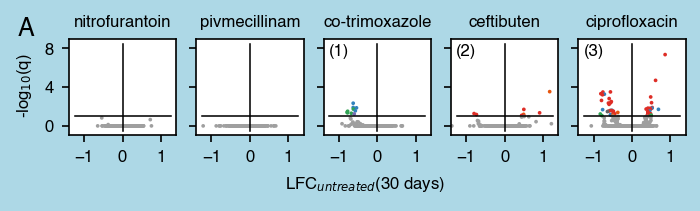

In [25]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(4.5, 1.25), facecolor='lightblue')
def _build_volcano_plot(figa, letter='A'):
    """
    Wraps the volcano plot
    """
    [[figy, fig], [_, figx]] = \
        figa.subfigures(2, 2, 
                       height_ratios=np.array([7, 1]) / 8 * 1.25,
                       width_ratios=[0.1, 4.4], 
                       facecolor='None')
    _plot_ancom_volcano(fig, recovery, 'color_c', ylabel='')
    sub_axes = fig.axes
    for i, ax_ in enumerate(sub_axes[2:]):
        ax_.text(ax_.get_xlim()[0] + 0.05 * np.diff(ax_.get_xlim()),
                 ax_.get_ylim()[1] - 0.05 * np.diff(ax_.get_ylim()),
                 f'({i+1:1.0f})',
                 ha='left', va='top', size=8)
                 
    ap._add_labelfig(figx, 'LFC$_{untreated}$(30 days)', fontsize=8)#, position=()
    ap._add_labelfig(figy, '-log$_{10}$(q)', fontsize=8, rotation=90)
    figy.axes[0].text(figy.axes[0].get_xlim()[0], 
                      figy.axes[0].get_ylim()[1],
                      letter, size=12, ha='left', va='top')
_build_volcano_plot(figa, letter='A')

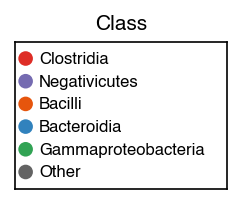

In [26]:
def _build_class_legend(figlc):
    """
    Puts together a class legend
    """
    axlc = figlc.add_subplot(1,1,1)
    axlc.xaxis.set_tick_params(**hide_axes)
    axlc.yaxis.set_tick_params(**hide_axes)
    axlc.set_xlim(0, 2)
    axlc.set_ylim(-0.75, 5.75)
    axlc.scatter(np.ones(6) * 0.1, 5 - np.arange(6), marker='o',
                 c=pd.Series(class_color)[class_order])
    for y, cl in enumerate(class_order):
        axlc.text(0.225, 5 - y, cl.split("__")[-1], 
                  size=8, ha='left', va='center')
    axlc.set_title('Class', size=10)
figlc = plt.figure(dpi=150, constrained_layout=True, figsize=(1.5, 1.25))
_build_class_legend(figlc)

## Forest plot (empress)

Due to some fun enviromental issues, I cant get empress to run  in this qiime2 enviroment, so I amy install an older version to get empress to work. ...Love when software versions dont stay up to date.

In [27]:
(ancom_res.drop(['0'], level='val')['q'] < 1e-1).groupby(['var', 'val']).sum().unstack()

val,1,2,3,4,5
var,,,,,
abx_code2,0,0,0,0,1
days_inv,0,0,10,8,48


In [28]:
all_taxa_p = taxa_q2.view(pd.Series).apply(lambda x: x.split(';')[1])
defined_taxa = all_taxa_p.loc[table.columns]
extra_taxa = all_taxa_p.drop(index=table.columns)
not_included = extra_taxa.loc[~extra_taxa.isin(defined_taxa.unique())].copy()
p_count = not_included.value_counts()
p_count[(p_count >= 25) & (p_count <= 75)]

Taxon
p__Bdellovibrionota       75
p__Marinisomatota         73
p__Deinococcota           69
p__Gemmatimonadota        68
p__Omnitrophota           57
p__Elusimicrobiota        55
p__Fusobacteriota         52
p__Thermotogota           48
p__Fibrobacterota         43
p__Verrucomicrobiota_A    41
p__Synergistota           40
p__Methylomirabilota      33
p__Firmicutes_G           33
p__Chloroflexota_A        31
p__Eremiobacterota        29
p__Dormibacterota         28
p__Armatimonadota         26
p__Firmicutes_K           26
p__Aquificota             25
Name: count, dtype: int64

In [29]:
big_ = np.abs(ancom_res.xs('days_inv', level='var')['lfc']).max()
big_ = np.ceil(big_ / 0.05) * 0.05
big_

1.5

In [30]:
space_phylum = 'p__Omnitrophota'
pad_ = extra_taxa.loc[extra_taxa.isin([space_phylum])].to_frame().copy()
pad_ = pad_.loc[pad_.index[:25]].copy()
pad_['lfc'] = 0.0
pad_.loc[pad_.index[0], 'lfc'] = -big_
pad_.loc[pad_.index[1], 'lfc'] = big_
pad_['se'] = np.nan
pad_['q'] = 1e-16
pad_['val'] = 1


pad2 = pd.concat(axis=0, objs=[pad_] * 3)
pad2['val'] = (pad2.groupby('Feature ID')['val'].cumsum() + 2).astype(str)
pad2.drop(columns=['Taxon'], inplace=True)
pad2.reset_index(inplace=True)
pad2.set_index(['val', 'Feature ID'], inplace=True)

In [31]:
ancom_res_emp = ancom_res.xs('days_inv', level='var').copy()
ancom_res_emp.drop(index=['0', '1', '2'], level='val', inplace=True)
ancom_res_emp.drop(columns=['tidy', 'q_tidy', 'passed_ss', 'diff', 'W', 'p'],
                   inplace=True)
ancom_res_emp_p = pd.concat([ancom_res_emp, pad2])
ancom_res_emp_p['sign'] = np.sign(ancom_res_emp_p['lfc'])
ancom_res_emp_p['log10_q'] = -np.log10(ancom_res_emp_p['q'])
ancom_res_emp_p['log_q_sc'] = \
    ancom_res_emp_p['log10_q'].mask(ancom_res_emp_p['log10_q'] <= 1, 0).mask(
        ancom_res_emp_p['log10_q'] >= 3, 3).round(2)
ancom_res_emp_p['log_q_sc'] = np.floor(ancom_res_emp_p['log_q_sc'])
ancom_res_emp_p.index.set_names(['abx', 'feature-id'], inplace=True)
ancom_res_emp_p.reset_index(inplace=True)
ancom_res_emp_p = ancom_res_emp_p.melt(
    id_vars=['abx', 'feature-id'],
    value_vars=['lfc', 'sign', 'q', 'log10_q', 'log_q_sc'],
    var_name='stat',
    )
ancom_res_emp_p['name'] = \
    ancom_res_emp_p.apply(lambda x: 'abx{abx}_{stat}'.format(**x), axis=1)
ancom_res_emp_p = ancom_res_emp_p.pivot(index='feature-id', 
                                        columns='name', 
                                        values='value')
emp_taxa = taxa_q2.view(pd.Series).apply(lambda x: pd.Series(x.split(';')))
emp_taxa = emp_taxa.loc[ancom_res_emp_p.index].add_prefix('t')
ancom_res_emp_p = pd.concat(axis=1, objs=[ancom_res_emp_p, emp_taxa])
ancom_res_emp_p['t2_group'] = ancom_res_emp_p['t2'].mask(
    ~ancom_res_emp_p['t2'].isin(class_order), 'c__Other')
ancom_res_emp_p['t4_group'] = ancom_res_emp_p['t4'].mask(
    ~ancom_res_emp_p['t4'].isin(cmap_fam.index), ancom_res_emp_p['t2_group'])
ancom_res_emp_p[['t2_group', 't4_group']] = \
    ancom_res_emp_p[['t2_group', 't4_group']].mask(
        ancom_res_emp_p['t1'].isin([space_phylum]), space_phylum)
ancom_res_emp_p[['abx3_sign', 'abx4_sign', 'abx5_sign']] = \
    ancom_res_emp_p[['abx3_sign', 'abx4_sign', 'abx5_sign']].mask(
        ancom_res_emp_p['t1'].isin([space_phylum]), 2)

ancom_res_emp_p['color'] = ancom_res_emp_p[['t2_group', 't4_group']].apply(lambda x: ';'.join(x), axis=1)
ancom_res_emp_p.to_csv('final-data/07.ancom-bc/emperor_meta.tsv', sep='\t')

I used the metadata in emperor to generate a figure. Illustrator was used to re-color the figure becuase emperor has not quite figured out how to let me do that either programatically or automagically. Someday... *sigh*.

To get to this point, i used empress in a qiime2-2023.2 release, and then ran

```{bash}
qiime empress tree-plot \
  --i-tree ./final-data/02.tables/matched_tree_gtdb.qza \
  --m-feature-metadata-file ./final-data/07.ancom-bc/emperor_meta.tsv \ 
  --p-shear-to-feature-metadata \
  --o-visualization ./final-data/07.ancom-bc/empress_tree_all.qzv
```

The file was opened in qiime2 view. I used a circular layout, colored the tree and first ring by the t2_group (class), colored the second ring by family (t4_group), and then plotted the log q colored by sign for cotrimaxazone, ceftibuten and ciprofloxacin. The whole thing got exported as a SVG. In the exported SVG, I merged color groups for the annotaiton rings (class, family, reference circles); deleted tips and markers for `p__Omnitrophota` and re-colored the tips and circles so they matched the colormap I wanted and not the automatic colormap. The original SVG and legend are in the final data, as are the cleaned up figures.

In [32]:
def _read_full_tree(fig, fp):
    """
    Reads in the modified adobe tree and plots the empress circular tree
    """
    # Sets up the axis
    ax = fig.add_subplot(1,1,1)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(**hide_axes)
    ax.set_position((0, 0, 1, 1))
    
    # Sets up the labeling
    ax.text(0.5, 0.5, 'Full ANCOM tree', ha='center', va='center', size=10)
    ax.text(0.025, 0.975, 'B', size=12, ha='left', va='top')
    

### Tree Legend

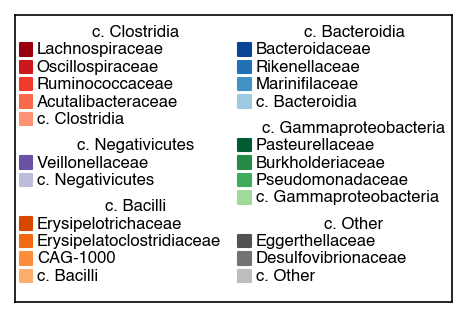

In [33]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 2))
def plot_fam_legend(fig):
    """
    Plots a family legend
    """
    axlf = fig.add_subplot(1,1,1)
    axlf.xaxis.set_tick_params(**hide_axes)
    axlf.yaxis.set_tick_params(**hide_axes)
    axlf.scatter(x='x', y='y', c='color', marker='s', data=cmap2)
    axlf.set_xlim(-0.05, 1.95)
    for l_, df in cmap2.iterrows():
        axlf.text(df['x'] + 0.05, df['y'], 
                  l_.replace('c__', 'c. ').replace('f__', '').replace('_', ' '),
                  ha='left', va='center', size=8)
    for phy_, [x, y] in cmap2.groupby('class')[['x', 'y']].first().iterrows():
        axlf.text(x + 0.5, y - 1, phy_.replace("__", '. ').replace('_', ' '),
                    ha='center', va='center', size=8)
    axlf.set_ylim(15.5, -1)
plot_fam_legend(fig)

## Significant clades

In [34]:
sig_clades = (ancom_res['q'] < 1e-1).groupby(['var', 'taxon']).any().unstack(0)
sig_clades_rec = np.hstack([sig_clades.index[sig_clades['days_inv']], 'RS.GCF.900155525.1'])

In [35]:
(ancom_res['q'] < 0.1).groupby(['var', 'val']).sum().drop(index=['0'], level='val').unstack()

val,1,2,3,4,5
var,,,,,
abx_code2,0,0,0,0,1
days_inv,0,0,10,8,48


In [36]:
ancom_res_sig = ancom_res[['lfc', 'se', 'q']].xs('days_inv', level='var').copy()
ancom_res_sig = \
    ancom_res_sig.loc[ancom_res_sig.index.to_frame()['taxon'].isin(sig_clades_rec)].copy()
ancom_res_sig.drop(['0', '1', '2'], level='val', inplace=True)
ancom_res_sig.reset_index(inplace=True)

ancom_res_sig['sign'] = np.sign(ancom_res_sig['lfc'])
ancom_res_sig2 = ancom_res_sig.melt(id_vars=['val', 'taxon'],
                                   value_vars=['lfc', 'se', 'q', 'sign'],
                                   var_name='stat')
ancom_res_sig2['s_wrap'] = \
    ancom_res_sig2[['val', 'stat']].apply(lambda x: 'abx{0}_{1}'.format(*x), axis=1)
ancom_res_sig2 = \
    ancom_res_sig2.pivot(index='taxon',
                         columns='s_wrap',
                        values='value')
sub_taxa = taxa_q2.view(pd.Series).loc[ancom_res_sig2.index]

ancom_res_sig2 = pd.concat(
    axis=1, 
    objs=[ancom_res_sig2, 
          sub_taxa.apply(lambda x: pd.Series(x.split(';'))).add_prefix('t')
          ]
    )
ancom_res_sig2['t2_group'] = ancom_res_sig2['t2'].mask(
    ~ancom_res_sig2['t2'].isin(class_order), 'c__Other')
ancom_res_sig2['t4_group'] = ancom_res_sig2['t4'].mask(
    ~ancom_res_sig2['t4'].isin(cmap_fam.index), ancom_res_sig2['t2_group'])
ancom_res_sig2.index.set_names('feature-id', inplace=True)

In [37]:
test_order = [
    'GB.GCA.000433735.1', 'RS.GCF.000158075.1', 'RS.GCF.003024655.1',
       'RS.GCF.000155435.1', 'RS.GCF.000424325.1', 'GB.GCA.000434275.1',
       'RS.GCF.000469345.1', 'RS.GCF.003122485.1', 'RS.GCF.001280875.1',
       'GB.GCA.000433535.1', 'RS.GCF.900142165.1', 'GB.GCA.900066545.1',
       'GB.GCA.900066145.1', 'RS.GCF.000157975.1', 'GB.GCA.900066135.1',
       'GB.GCA.900066075.1', 'GB.GCA.002361775.1', 'RS.GCF.900120295.1',
       'GB.GCA.001304935.1', 'RS.GCF.000373885.1', 'RS.GCF.002549975.1',
       'GB.GCA.002313795.1', 'GB.GCA.003293635.1', 'GB.GCA.003312465.1',
       'RS.GCF.002549755.1', 'RS.GCF.002549775.1', 'GB.GCA.002437735.1',
       'GB.GCA.900317525.1', 'GB.GCA.002438575.1', 'GB.GCA.000435555.1',
       'GB.GCA.002404605.1', 'GB.GCA.002298695.1', 'GB.GCA.002437575.1',
       'GB.GCA.000437375.1', 'GB.GCA.003150215.1', 'GB.GCA.000435275.1',
       'GB.GCA.000431775.1', 'GB.GCA.900315555.1', 'RS.GCF.002959915.1',
        'RS.GCF.000371425.1', 'RS.GCF.000157995.1', 'RS.GCF.000154485.1',
       'GB.GCA.003150195.1', 'RS.GCF.000210055.1', 'RS.GCF.000024265.1',
       'RS.GCF.900155525.1', 'RS.GCF.003252795.1', 'RS.GCF.001815355.1',
       'RS.GCF.000210895.1', 'RS.GCF.000191405.1', 'RS.GCF.001457615.1',
       'RS.GCF.000205025.1', 'GB.GCA.000980495.1', 'RS.GCF.000315425.1',
       'RS.GCF.900240235.1', 'RS.GCF.000786575.1', 'RS.GCF.000210575.1',
       'GB.GCA.001915615.1', 'RS.GCF.002222615.2', 'RS.GCF.001314995.1',
       'RS.GCF.000156075.1', 'RS.GCF.000233955.1', 'GB.GCA.002298815.1',
       'GB.GCA.002449845.1'
    
    ]

In [38]:
ancom_res_sig3 = ancom_res_sig.copy()
ancom_res_sig3['c'] = '#252525'
ancom_res_sig3['fc'] = ancom_res_sig3['c'].mask(ancom_res_sig3['q'] >= 0.1, 'w')
ancom_res_sig3['mark'] = 's'
ancom_res_sig3.set_index('taxon', inplace=True)
ancom_res_sig3 = pd.concat(
    axis=1, 
    objs=[ancom_res_sig3, 
          sub_taxa.loc[ancom_res_sig3.index].apply(lambda x: pd.Series(x.split(';'))).add_prefix('t')
         ])
ancom_res_sig3 = ancom_res_sig3.loc[test_order]
# ancom_res_sig3.sort_values(['t0', 't1', 't2', 't3', 't4', 't5', 't6', 'val',], ascending=True, inplace=True)
ancom_res_sig3.set_index(['val'], inplace=True, append=True)
ancom_res_sig3['y'] = 1
ancom_res_sig3['y'] = ancom_res_sig3.groupby('val', sort=False)['y'].cumsum()
ancom_res_sig3['y'] = ancom_res_sig3['y'].max() - ancom_res_sig3['y']
ancom_res_sig3['width'] = ancom_res_sig3['se'] * 1.96
ancom_res_sig3['t2_group'] = ancom_res_sig3['t2'].mask(
    ~ancom_res_sig3['t2'].isin(class_order), 'c__Other')
ancom_res_sig3['t4_group'] = ancom_res_sig3['t4'].mask(
    ~ancom_res_sig3['t4'].isin(cmap_fam.index), ancom_res_sig3['t2_group'])

# ancom_res_sig3['sp'] = ancom_res_sig3['sp'].apply(lambda x: x.replace("s__", '').replace("_", ' '))

In [39]:
def _tidy_rf3(x):
    y = '{0} ({1} {2})'.format(*x)
    y = y.replace("__", '. ').replace('s. ', 's__')
    return y

ancom_res_sig3['sp'] = ancom_res_sig3['t6'].mask(
    ancom_res_sig3['t5'].apply(lambda x: ('CAG' in x) | ('ER' in x) | ('UBA' in x) | ('RUG' in x)), 
    ancom_res_sig3[['t6', 't4']].apply(
        lambda x: '{0} ({1})'.format(*x).replace("f__", 'f. '), axis=1)
    )
ancom_res_sig3['sp'] = ancom_res_sig3['sp'].mask(
    ancom_res_sig3['t4'].apply(lambda x: 'CAG' in x), 
    ancom_res_sig3[['t6', 't3']].apply(
        lambda x: '{0} ({1})'.format(*x).replace("o__", 'o. '), axis=1)
    )
ancom_res_sig3['sp'] = \
    ancom_res_sig3['sp'].mask(ancom_res_sig3['t3'].apply(lambda x: 'o__RF39' in x), 
                              ancom_res_sig3[['t6', 't2', 't3']].apply(_tidy_rf3, axis=1)
                              )
ancom_res_sig3['sp'] = ancom_res_sig3['sp'].mask(
    ancom_res_sig3['t4_group'].apply(lambda x: 'c__' in x) & 
    ~ancom_res_sig3['sp'].apply(lambda x: '. ' in x),
    ancom_res_sig3[['t6', 't4']].apply(
        lambda x: '{0} ({1})'.format(*x).replace("f__", 'f. '), axis=1)
    )
ancom_res_sig3['sp'] = ancom_res_sig3['sp'].apply(lambda x: x.replace("s__", '').replace("_", ' '))
ancom_res_sig3.index.set_names(['feature-id', 'abx'], inplace=True)

In [40]:
# ancom_res_sig3['t4_group'].drop_duplicates()#.apply(lambda x: 'c__' in x)

In [41]:
ancom_res_sig3['c2'] = ancom_res_sig3['t4_group'].replace(cmap_fam)
ancom_res_sig3['fc2'] = ancom_res_sig3['c2'].mask(ancom_res_sig3['q'] >= 0.1, 'w')

In [42]:
ancom_res_sig3 = ancom_res_sig3.sort_index(level=['feature-id', 'abx']).loc[test_order]
ancom_res_sig3['y2'] = 1 + \
    (~ancom_res_sig3['t2'].duplicated(keep='first')) * 1 + \
    (~ancom_res_sig3['t4_group'].duplicated(keep='first')) * 1
ancom_res_sig3['y2'] = ancom_res_sig3['y2'] * ancom_res_sig3.index.to_frame()['abx'].isin([3, '3'])
ancom_res_sig3['y2'] = ancom_res_sig3['y2'].cumsum()
ancom_res_sig3['y2'] = ancom_res_sig3['y2'].max() - ancom_res_sig3['y2']

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


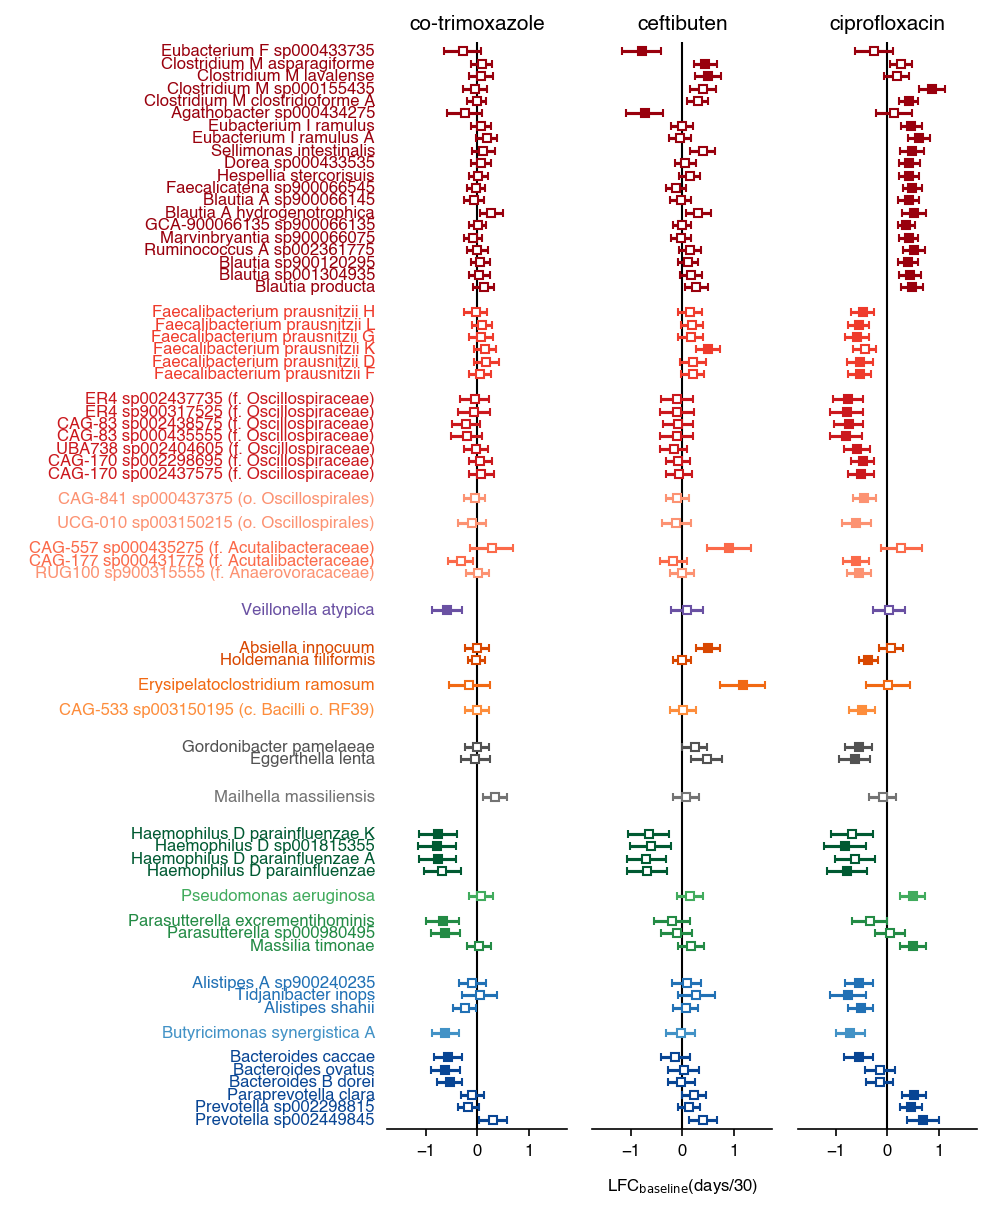

In [67]:
forest_kwargs = dict(linestyle='',  capsize=2, markersize=4, y='y2', x='lfc', xerr='width')

fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 8))
gs = fig.add_gridspec(2, 4, width_ratios=[2, 1, 1, 1], height_ratios=[8.75, 0.25])

axt = fig.add_subplot(gs[0, 0], facecolor='None')
axt.yaxis.set_tick_params(left=False, labelleft=False, right=False, labelright=False, labelsize=8, length=0)
axt.xaxis.set_tick_params(left=False, labelleft=False, right=False, labelright=False, length=0, labelsize=0)

for i, (abx, abx_df) in enumerate(ancom_res_sig3.groupby('abx')):
    ax = fig.add_subplot(gs[0, i + 1], sharey=axt) 
    ax.set_yticks(abx_df['y2'])
    ax.set_yticklabels(abx_df['sp'])
    ax.set_ylim(abx_df['y2'].min() - 0.75, abx_df['y2'].max() + 0.75)
    ax.plot([0, 0], [abx_df['y2'].min() - 5, abx_df['y2'].max() + 5], 'k', 
            linestyle='-', linewidth=1)
    ax.yaxis.set_tick_params(left=False, labelleft=False, 
                             right=False, labelright=False,
                             labelsize=0, length=0,
                             gridOn=False)
    ax.xaxis.set_tick_params(bottom=True, labelbottom=True,
                             top=False, labeltop=False, labelsize=8)
    for (c, fc, m), df_ in abx_df.groupby(['c2', 'fc2', 'mark']):
        ax.errorbar(data=df_, color=c, markerfacecolor=fc, marker=m, 
                    **forest_kwargs)
    ax.set_title(abx_names[abx], size=10)
lims = np.hstack([ax.get_xlim() for ax in fig.axes])
lims = np.max(np.absolute(lims))
for ax in fig.axes[1:]:
    ax.set_xlim(-lims, lims)
    sn.despine(ax=ax, left=True, right=True, bottom=False, top=True)

axt.set_xlim(0, 1)
for _, [y2, sp, c] in abx_df[['y2', 'sp', 'c2']].iterrows():
    axt.text(x=1, y=y2, s=sp, size=8, ha='right', va='center', color=c)
sn.despine(ax=axt, left=True, right=True, top=True, bottom=True)
    
axx = fig.add_subplot(gs[1, 1:], facecolor='None')
axx.xaxis.set_tick_params(**hide_axes)
axx.yaxis.set_tick_params(**hide_axes)
axx.set_xlim(0, 1)
axx.set_ylim(0, 1)
axx.text(0.5, 0.5, 'LFC$_{\\mathrm{baseline}}$(days/30)', 
         ha='center', va='center', size=8)
sn.despine(ax=axx, left=True, right=True, top=True, bottom=True)
fig.savefig('output/figures/figure_s11_ancom_forest.png', dpi=600, facecolor='None')
fig.savefig('output/figures/figure_s11_ancom_forest.pdf', dpi=600, facecolor='None')


In [44]:
cotrim_sig = ancom_res_sig3.xs('3', level='abx')
cotrim_sig.loc[cotrim_sig['q'] < 0.1, ['lfc', 't4', 't5', 't6']]

,lfc,t4,t5,t6
feature-id,,,,
RS.GCF.002959915.1,-0.601092,f__Veillonellaceae,g__Veillonella,s__Veillonella atypica
RS.GCF.003252795.1,-0.774770,f__Pasteurellaceae,g__Haemophilus_D,s__Haemophilus_D parainfluenzae_K
RS.GCF.001815355.1,-0.786111,f__Pasteurellaceae,g__Haemophilus_D,s__Haemophilus_D sp001815355
RS.GCF.000210895.1,-0.771810,f__Pasteurellaceae,g__Haemophilus_D,s__Haemophilus_D parainfluenzae_A
RS.GCF.000205025.1,-0.676363,f__Burkholderiaceae,g__Parasutterella,s__Parasutterella excrementihominis
GB.GCA.000980495.1,-0.623552,f__Burkholderiaceae,g__Parasutterella,s__Parasutterella sp000980495
GB.GCA.001915615.1,-0.627348,f__Marinifilaceae,g__Butyricimonas,s__Butyricimonas synergistica_A
RS.GCF.002222615.2,-0.571701,f__Bacteroidaceae,g__Bacteroides,s__Bacteroides caccae
RS.GCF.001314995.1,-0.626967,f__Bacteroidaceae,g__Bacteroides,s__Bacteroides ovatus


In [45]:
ceftibuten_sig = ancom_res_sig3.xs('4', level='abx').copy()
ceftibuten_sig['sign'] = np.sign(ceftibuten_sig['lfc'])
ceftibuten_sig.loc[ceftibuten_sig['q'] < 0.1, ['lfc', 'sign', 't2', 't3', 't4', 't5', 't6']].sort_values(['t2', 'sign', 't4'])

,lfc,sign,t2,t3,t4,t5,t6
feature-id,,,,,,,
RS.GCF.000154485.1,1.171579,1.0,c__Bacilli,o__Erysipelotrichales,f__Erysipelatoclostridiaceae,g__Erysipelatoclostridium,s__Erysipelatoclostridium ramosum
RS.GCF.000371425.1,0.493791,1.0,c__Bacilli,o__Erysipelotrichales,f__Erysipelotrichaceae,g__Absiella,s__Absiella innocuum
GB.GCA.000433735.1,-0.796261,-1.0,c__Clostridia,o__Lachnospirales,f__Lachnospiraceae,g__Eubacterium_F,s__Eubacterium_F sp000433735
GB.GCA.000434275.1,-0.734553,-1.0,c__Clostridia,o__Lachnospirales,f__Lachnospiraceae,g__Agathobacter,s__Agathobacter sp000434275
GB.GCA.000435275.1,0.909553,1.0,c__Clostridia,o__Oscillospirales,f__Acutalibacteraceae,g__CAG-557,s__CAG-557 sp000435275
RS.GCF.000158075.1,0.443576,1.0,c__Clostridia,o__Lachnospirales,f__Lachnospiraceae,g__Clostridium_M,s__Clostridium_M asparagiforme
RS.GCF.003024655.1,0.500363,1.0,c__Clostridia,o__Lachnospirales,f__Lachnospiraceae,g__Clostridium_M,s__Clostridium_M lavalense
GB.GCA.003312465.1,0.499010,1.0,c__Clostridia,o__Oscillospirales,f__Ruminococcaceae,g__Faecalibacterium,s__Faecalibacterium prausnitzii_K


In [46]:
cipro_sig = ancom_res_sig3.xs('5', level='abx').copy()
cipro_sig['sign'] = np.sign(cipro_sig['lfc'])
cipro_sig = cipro_sig.loc[cipro_sig['q'] < 0.1, ['lfc', 'sign', 't2', 't4', 't5', 't6']].sort_values(['t2', 'sign', 't4'])
cipro_sig['t2'].value_counts()

t2
c__Clostridia             32
c__Bacteroidia             8
c__Gammaproteobacteria     4
c__Bacilli                 2
c__Coriobacteriia          2
Name: count, dtype: int64

In [47]:
cipro_sig.loc[cipro_sig['t2'] == 'c__Bacilli']

,lfc,sign,t2,t4,t5,t6
feature-id,,,,,,
GB.GCA.003150195.1,-0.495154,-1.0,c__Bacilli,f__CAG-1000,g__CAG-533,s__CAG-533 sp003150195
RS.GCF.000157995.1,-0.370112,-1.0,c__Bacilli,f__Erysipelotrichaceae,g__Holdemania,s__Holdemania filiformis


In [48]:
cipro_sig.loc[cipro_sig['t2'] == 'c__Gammaproteobacteria']

,lfc,sign,t2,t4,t5,t6
feature-id,,,,,,
RS.GCF.001815355.1,-0.826221,-1.0,c__Gammaproteobacteria,f__Pasteurellaceae,g__Haemophilus_D,s__Haemophilus_D sp001815355
RS.GCF.000191405.1,-0.783019,-1.0,c__Gammaproteobacteria,f__Pasteurellaceae,g__Haemophilus_D,s__Haemophilus_D parainfluenzae
RS.GCF.000315425.1,0.497631,1.0,c__Gammaproteobacteria,f__Burkholderiaceae,g__Massilia,s__Massilia timonae
RS.GCF.001457615.1,0.492210,1.0,c__Gammaproteobacteria,f__Pseudomonadaceae,g__Pseudomonas,s__Pseudomonas aeruginosa


In [49]:
cipro_sig.loc[(cipro_sig['sign'] < 0) & ~cipro_sig['t2'].isin(['c__Clostridia'])]

,lfc,sign,t2,t4,t5,t6
feature-id,,,,,,
GB.GCA.003150195.1,-0.495154,-1.0,c__Bacilli,f__CAG-1000,g__CAG-533,s__CAG-533 sp003150195
RS.GCF.000157995.1,-0.370112,-1.0,c__Bacilli,f__Erysipelotrichaceae,g__Holdemania,s__Holdemania filiformis
RS.GCF.002222615.2,-0.562363,-1.0,c__Bacteroidia,f__Bacteroidaceae,g__Bacteroides,s__Bacteroides caccae
GB.GCA.001915615.1,-0.720295,-1.0,c__Bacteroidia,f__Marinifilaceae,g__Butyricimonas,s__Butyricimonas synergistica_A
RS.GCF.900240235.1,-0.554340,-1.0,c__Bacteroidia,f__Rikenellaceae,g__Alistipes_A,s__Alistipes_A sp900240235
RS.GCF.000786575.1,-0.764837,-1.0,c__Bacteroidia,f__Rikenellaceae,g__Tidjanibacter,s__Tidjanibacter inops
RS.GCF.000210575.1,-0.519135,-1.0,c__Bacteroidia,f__Rikenellaceae,g__Alistipes,s__Alistipes shahii
RS.GCF.000210055.1,-0.564093,-1.0,c__Coriobacteriia,f__Eggerthellaceae,g__Gordonibacter,s__Gordonibacter pamelaeae
RS.GCF.000024265.1,-0.640212,-1.0,c__Coriobacteriia,f__Eggerthellaceae,g__Eggerthella,s__Eggerthella lenta


In [50]:
cipro_sig.loc[(cipro_sig['sign'] < 0) & cipro_sig['t2'].isin(['c__Bacteroidia']), 't6'].apply(lambda x: x.replace('s__', '').replace("_", ' ')).values

array(['Bacteroides caccae', 'Butyricimonas synergistica A',
       'Alistipes A sp900240235', 'Tidjanibacter inops',
       'Alistipes shahii'], dtype=object)

In [51]:
cipro_sig.loc[(cipro_sig['sign'] < 0) & cipro_sig['t2'].isin(['c__Clostridia'])].shape

(16, 6)

In [52]:
cipro_sig.loc[(cipro_sig['sign'] > 0) & ~cipro_sig['t2'].isin(['c__Clostridia'])]

,lfc,sign,t2,t4,t5,t6
feature-id,,,,,,
RS.GCF.000233955.1,0.519859,1.0,c__Bacteroidia,f__Bacteroidaceae,g__Paraprevotella,s__Paraprevotella clara
GB.GCA.002298815.1,0.458304,1.0,c__Bacteroidia,f__Bacteroidaceae,g__Prevotella,s__Prevotella sp002298815
GB.GCA.002449845.1,0.687464,1.0,c__Bacteroidia,f__Bacteroidaceae,g__Prevotella,s__Prevotella sp002449845
RS.GCF.000315425.1,0.497631,1.0,c__Gammaproteobacteria,f__Burkholderiaceae,g__Massilia,s__Massilia timonae
RS.GCF.001457615.1,0.492210,1.0,c__Gammaproteobacteria,f__Pseudomonadaceae,g__Pseudomonas,s__Pseudomonas aeruginosa


In [53]:
cipro_sig.loc[(cipro_sig['sign'] > 0) & cipro_sig['t2'].isin(['c__Clostridia'])].shape

(16, 6)

## Clostridia

In [54]:
test_tree_q2, = q2_phylogeny.filter_tree(tree=tree_q2, metadata=Metadata(ancom_res_emp_p))

In [55]:
test_tree_firm_q2, = q2_phylogeny.filter_tree(test_tree_q2, 
                                              metadata=Metadata(ancom_res_emp_p), 
                                              where='[t2]="c__Clostridia"')

In [56]:
keep_firm = (ancom_res_emp_p['t2'].isin(['c__Clostridia']) | 
             (np.abs(ancom_res_emp_p['abx3_lfc']) == 1.5))
firma_all = ancom_res_emp_p.loc[keep_firm].copy()
firma_all.drop(columns=[c for c in firma_all.columns if 'abx3' in c],
               inplace=True)
firma_all.drop(columns=[c for c in firma_all.columns if 'abx4' in c],
               inplace=True)
firma_all['abx5_sign'] = np.sign(firma_all['abx5_lfc'])
firma_all['abx5_lfc'] = firma_all['abx5_lfc'].mask(
    np.absolute(firma_all['abx5_lfc']) > 1, firma_all['abx5_sign'])
firma_all['abx5_lfc_r'] = \
    (np.ceil((np.absolute(firma_all['abx5_lfc']) - 0.05) / 10) * 0.1 ) * \
    firma_all['abx5_sign']
firma_all['abx5_lfc_abs'] = np.abs(firma_all['abx5_lfc'])
firma_all['t4_group3'] = firma_all['t4_group'].mask(firma_all['t4_group'].isin(['c__Clostridia']), firma_all['t3'])

firma_sig = firma_all.loc[(firma_all['abx5_q'] < 0.1) & firma_all['t2'].isin(['c__Clostridia'])].copy()


In [57]:
np.linspace(-1, 1, 21)

array([-1. , -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1,  0. ,
        0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ])

In [58]:
firma_all.to_csv('./final-data/07.ancom-bc/firma_all.tsv', sep='\t')
firma_sig.to_csv('./final-data/07.ancom-bc/firmicutes_a_sig.tsv', sep='\t')

In [59]:
firma_sig['t3'].value_counts()

t3
o__Lachnospirales          16
o__Oscillospirales         15
o__Peptostreptococcales     1
Name: count, dtype: int64

In [60]:
firma_sig['t4'].value_counts()

t4
f__Lachnospiraceae       16
f__Oscillospiraceae       7
f__Ruminococcaceae        5
f__Acutalibacteraceae     1
f__CAG-272                1
f__CAG-382                1
f__Anaerovoracaceae       1
Name: count, dtype: int64

In [61]:
mean = np.linspace(-1, 1, 21)
step = np.diff(mean[[0, 1]]) / 2
left_ = mean - step
right_ =  mean + step

In [62]:
mean

array([-1. , -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1,  0. ,
        0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ])

In [63]:
colors = [mpc.to_hex(c) for c in sn.color_palette('RdBu_r', len(left_))]

In [64]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 1), facecolor='None')
def plot_lfc_cmap(fig):
    """
    Makes the log fold change heatmap
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.barh(left=left_,
            y=0,
            width=step * 2,
            color=colors,
            height=0.15)
    ax.plot(np.vstack([[-1, -0.5, 0, 0.5, 1]] * 2),
            np.vstack([np.ones(5) * -1, np.ones(5)]) * 0.0375 + 0.15 / 2,
            color='k',
            linewidth=1,
            )
    for x in [-1, -0.5, 0, 0.5, 1]:
        ax.text(x, 0.175, f'{x:1.1f}', ha='center', va='center', size=8)
    ax.text(0, 0.25, s='LFC$_{untreated}$(30 days)', ha='center', va='bottom', size=9)
    
    ax.set_ylim(-0.5, 0.4)
    ax.set_xlim(-1.25, 3.1)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=False, top=False, labeltop=False, labelsize=0, length=0)
    ax.yaxis.set_tick_params(bottom=False, labelbottom=False, top=False, labeltop=False, labelsize=0, length=0)

<Figure size 450x150 with 0 Axes>

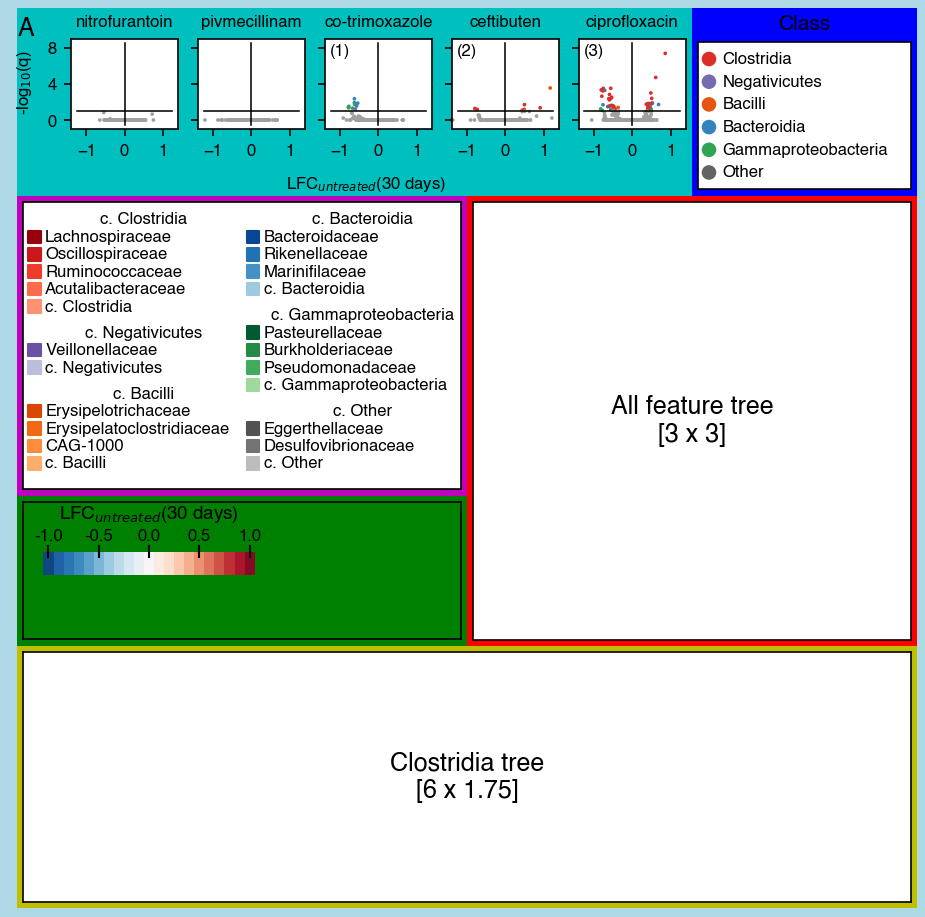

In [65]:
def _label_fig(fig, label, rotation=0):
    """
    Helper to label function
    """
    ax = fig.add_subplot(1,1,1)
    ax.xaxis.set_tick_params(**ap.hide_axes)
    ax.yaxis.set_tick_params(**ap.hide_axes)
    ax.text(0.5, 0.5, label, rotation=rotation, ha='center', va='center', size=12)

fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 6), facecolor='lightblue')
fig0, fig1 = fig.subfigures(2, 1, height_ratios=[1.25, 3 + 1.75], facecolor='None', wspace=0, hspace=0)
figvol, figvoll = fig0.subfigures(1, 2, width_ratios=[4.5, 1.5], facecolor='None', wspace=0, hspace=0)
fig10, fig11 = fig1.subfigures(2, 1, height_ratios=[3, 1.75], facecolor='None', wspace=0, hspace=0)
fig100, figatree = fig10.subfigures(1, 2, width_ratios=[1, 1], facecolor='None', wspace=0, hspace=0)
[figal, figsl] = fig100.subfigures(2, 1, height_ratios=[2, 1], facecolor='None', wspace=0, hspace=0)

_build_volcano_plot(figvol, letter='A')
figvol.set_facecolor('c')
_build_class_legend(figvoll)
figvoll.set_facecolor('b')
_label_fig(figatree, 'All feature tree\n[3 x 3]')
_label_fig(figal, 'Family/Class legend\n[3 x 2]')
figatree.set_facecolor('r')
figal.set_facecolor('m')
figsl.set_facecolor('g')
plot_fam_legend(figal)
plot_lfc_cmap(figsl)
_label_fig(fig11, 'Clostridia tree\n[6 x 1.75]')
fig11.set_facecolor('y')

In [66]:
fig.savefig('output/figures/Figure_3_ancom_bc_rough.pdf',
            dpi=300)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped
